In [2]:
from pathlib import Path

from IPython.display import display, Image
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
import sklearn

path = Path('cls.dat')
if not path.is_file():
    raise FileNotFoundError('Upload the original cls.dat to the notebook working directory first.')
data = np.loadtxt(path, skiprows=1)
X = data[:, :2]
y = data[:, 2].astype(int)
assert data.shape == (800, 3) and np.isfinite(data).all()
assert set(np.unique(data[:, 2])) == {0, 1}
print('Observations:', len(y))
print('Class counts:', dict(zip(*np.unique(y, return_counts=True))))
print('scikit-learn version:', sklearn.__version__)

Observations: 800
Class counts: {np.int64(0): np.int64(377), np.int64(1): np.int64(423)}
scikit-learn version: 1.8.0


## 4(a) Plot the observations
Red marks represent class 1 and blue marks represent class 0. The original feature coordinates are used for all models and plots.

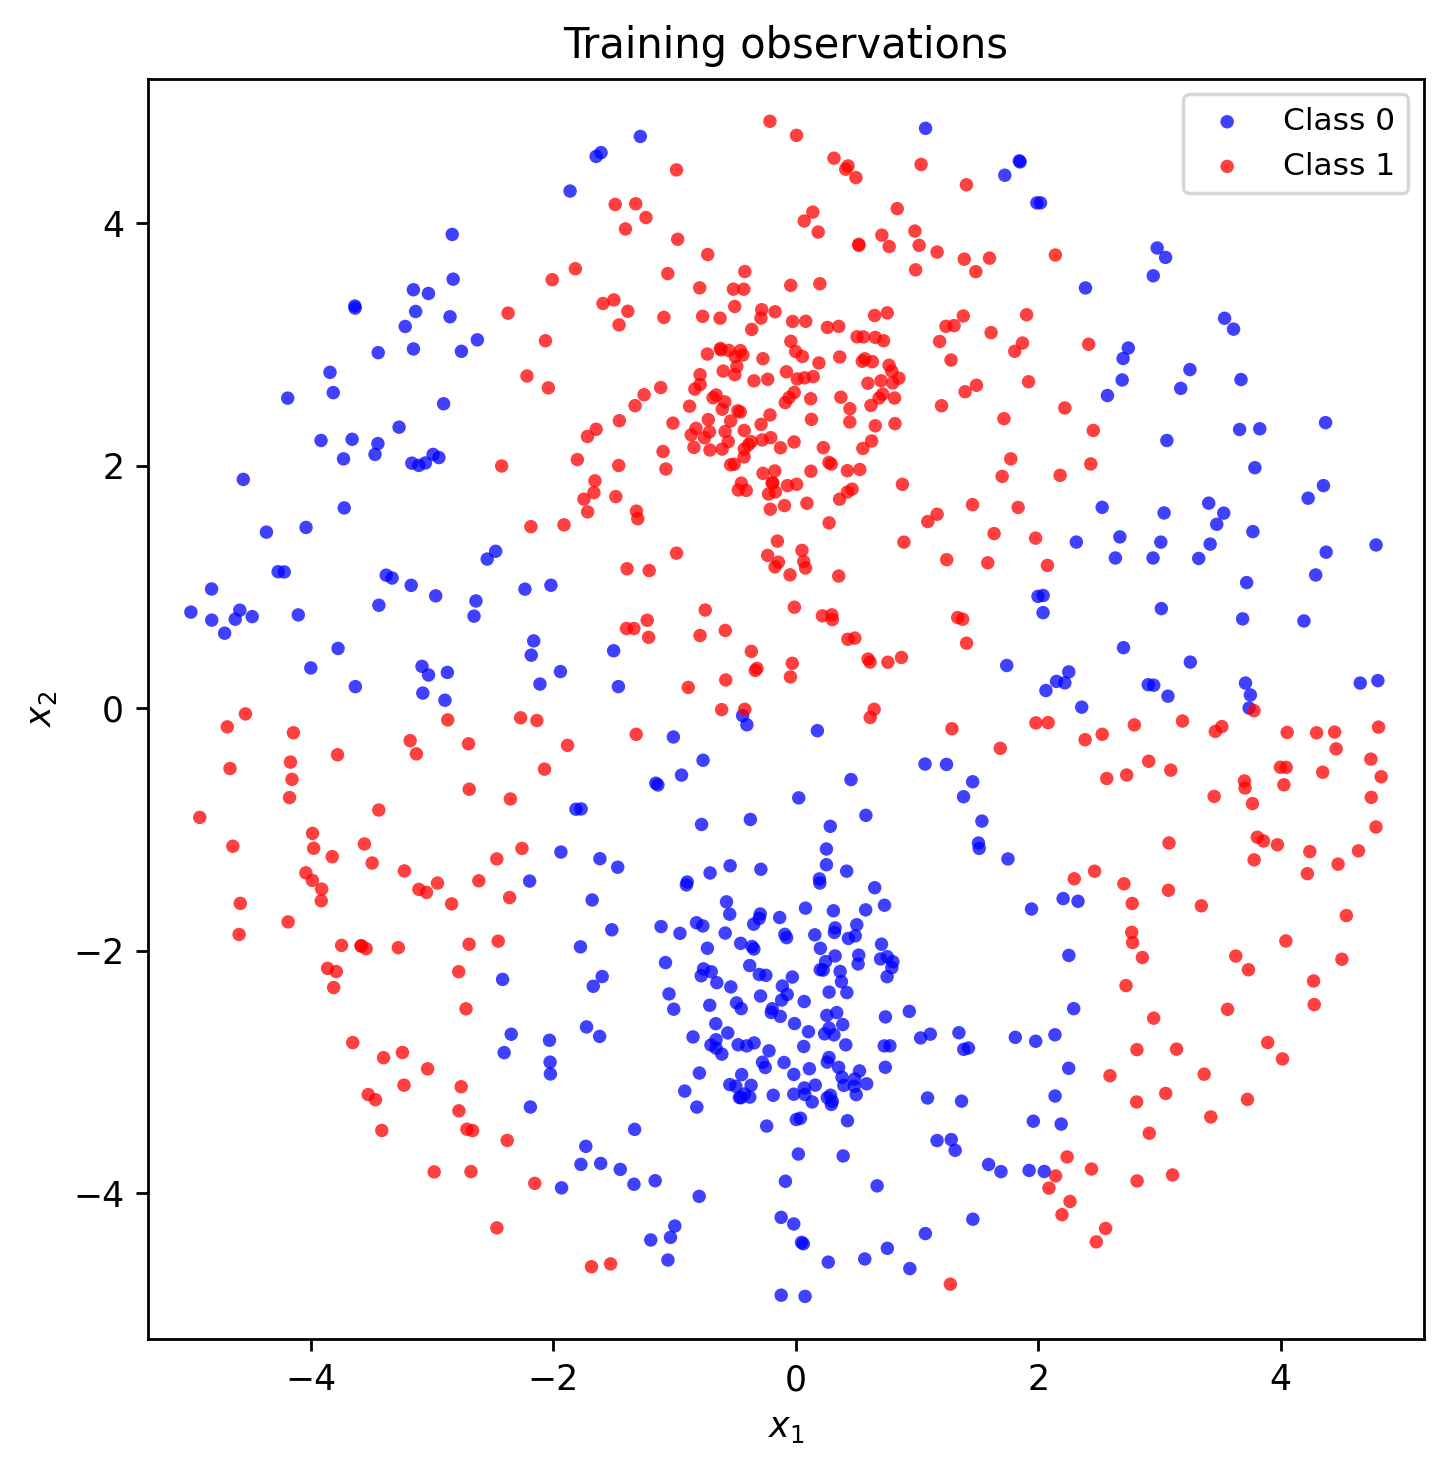

In [3]:
def draw_data(ax):
    for label, color in [(0, 'blue'), (1, 'red')]:
        ax.scatter(X[y == label, 0], X[y == label, 1], c=color,
                   s=15, alpha=0.75, label=f'Class {label}', edgecolors='none')
    ax.set(xlabel='$x_1$', ylabel='$x_2$', xlim=(X[:,0].min()-.35, X[:,0].max()+.35),
           ylim=(X[:,1].min()-.35, X[:,1].max()+.35), aspect='equal')
    ax.legend(loc='upper right', fontsize=9)

fig, ax = plt.subplots(figsize=(7, 6))
draw_data(ax)
ax.set_title('Training observations')
fig.tight_layout()
fig.savefig('q4a_data.png', dpi=250, bbox_inches='tight')
display(Image(filename='q4a_data.png'))
plt.close(fig)

xx, yy = np.meshgrid(np.linspace(X[:,0].min()-.35, X[:,0].max()+.35, 400),
                     np.linspace(X[:,1].min()-.35, X[:,1].max()+.35, 400))
mesh = np.c_[xx.ravel(), yy.ravel()]

def draw_boundary(score, title, filename):
    fig, ax = plt.subplots(figsize=(7, 6))
    Z = score(mesh).reshape(xx.shape)
    ax.contour(xx, yy, Z, levels=[0], colors='black', linewidths=1.8)
    draw_data(ax)
    ax.plot([], [], color='black', label='Decision boundary')
    ax.legend(loc='upper right', fontsize=9)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(filename, dpi=250, bbox_inches='tight')
    display(Image(filename=filename))
    plt.close(fig)

## 4(b) Linear logistic regression
Minimize the mean binary cross-entropy with no L2 penalty (lambda = 0). For design matrix A = [X, 1] and coefficient vector theta = [w1,w2,b], the gradient is A.T @ (sigmoid(A @ theta) - y)/n. BFGS uses this analytical gradient. The zero score contour is the probability 0.5 decision boundary. Convexity and a near-zero gradient provide evidence of an optimum.

Converged: True Optimization terminated successfully.
Weights: [0.04414541 0.32689615] Intercept: 0.13373647041339612
Mean training log loss: 0.6195333436934063
Gradient infinity norm: 9.408921836095985e-12
Design matrix rank: 3
Training accuracy: 67.0000%
Confusion matrix (labels 0,1):
 [[234 143]
 [121 302]]


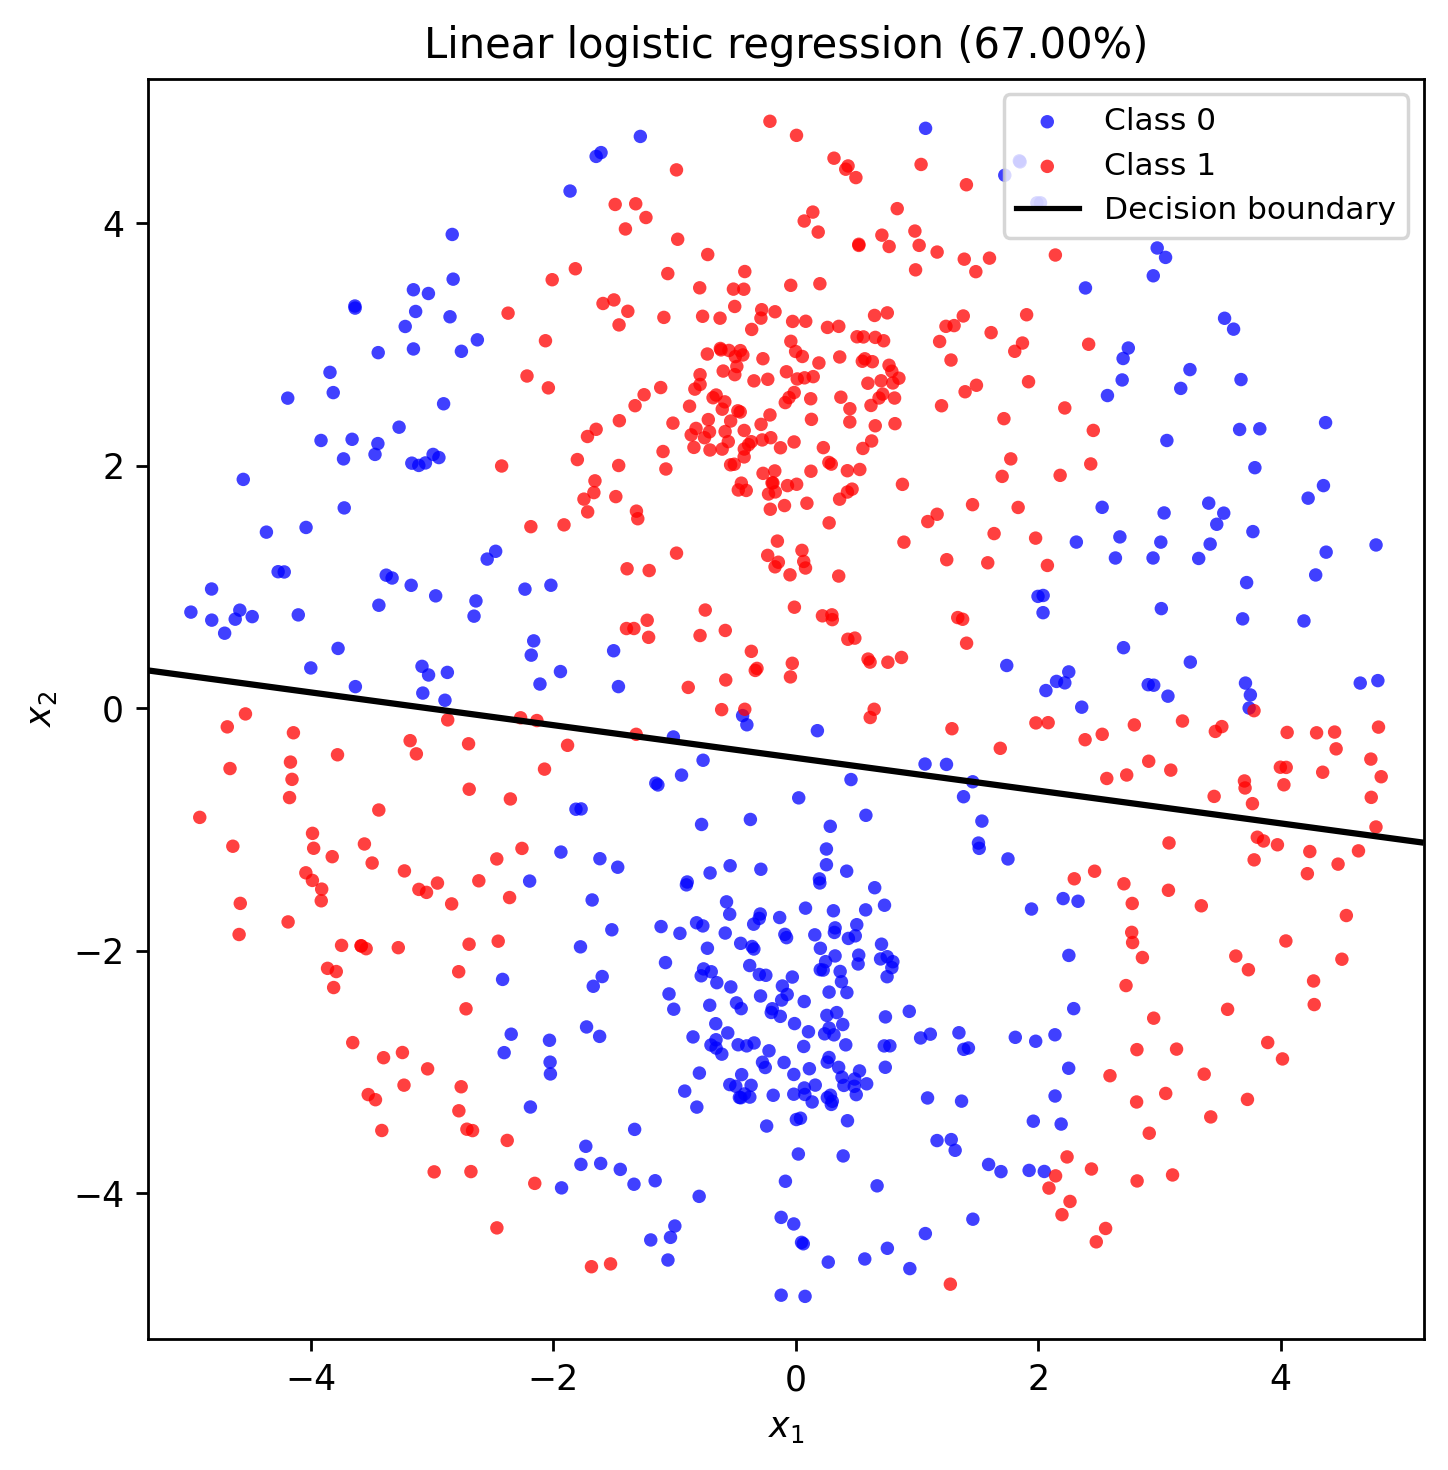

In [4]:
A = np.c_[X, np.ones(len(y))]
def logistic_objective(theta):
    z = A @ theta
    loss = np.mean(np.logaddexp(0, z) - y*z)
    grad = A.T @ (expit(z) - y) / len(y)
    return loss, grad

result = minimize(logistic_objective, np.zeros(3), jac=True, method='BFGS',
                  options={'gtol': 1e-10, 'maxiter': 2000})
w, b = result.x[:2], result.x[2]
log_score = lambda points: points @ w + b
log_pred = (log_score(X) >= 0).astype(int)
print('Converged:', result.success, result.message)
print('Weights:', w, 'Intercept:', b)
print('Mean training log loss:', result.fun)
print('Gradient infinity norm:', np.linalg.norm(result.jac, np.inf))
print('Design matrix rank:', np.linalg.matrix_rank(A))
print(f'Training accuracy: {accuracy_score(y, log_pred):.4%}')
print('Confusion matrix (labels 0,1):\n', confusion_matrix(y, log_pred, labels=[0,1]))
draw_boundary(log_score, f'Linear logistic regression ({accuracy_score(y, log_pred):.2%})', 'q4b_logistic.png')

## SVM search helper


In [5]:
def search_svm(kernel, grid):
    results = []
    best_model, best_params, best_acc = None, None, -1.0
    for params in grid:
        model = SVC(kernel=kernel, tol=1e-4, max_iter=2_000_000, **params)
        model.fit(X, y)
        acc = accuracy_score(y, model.predict(X))
        results.append({**params, 'accuracy': acc, 'converged': model.fit_status_ == 0,
                        'support_vectors': len(model.support_)})
        if model.fit_status_ == 0 and acc > best_acc:
            best_model, best_params, best_acc = model, params, acc
    table = pd.DataFrame(results).sort_values('accuracy', ascending=False, kind='stable')
    if best_model is None:
        raise RuntimeError('No candidate converged')
    return best_model, best_params, table

def report_svm(model, params):
    pred = model.predict(X)
    print('Chosen parameters:', params)
    print(f'Training accuracy: {accuracy_score(y, pred):.4%}')
    print('Correct predictions:', np.sum(pred == y), '/', len(y))
    print('Support vectors:', len(model.support_))
    print('Solver converged:', model.fit_status_ == 0)
    print('Iterations:', model.n_iter_)
    print('Confusion matrix (labels 0,1):\n', confusion_matrix(y, pred, labels=[0,1]))

## 4(c) Linear SVM
The linear kernel is the ordinary dot product. C controls the balance between the margin regularizer and the sum of hinge losses.

,C,accuracy,converged,support_vectors
3,10.00,0.70875,True,579
4,100.00,0.70875,True,579
2,1.00,0.70625,True,578
1,0.10,0.70375,True,581
0,0.01,0.69875,True,595


Chosen parameters: {'C': 10}
Training accuracy: 70.8750%
Correct predictions: 567 / 800
Support vectors: 579
Solver converged: True
Iterations: [33618]
Confusion matrix (labels 0,1):
 [[258 119]
 [114 309]]
Weights: [0.13143766 0.38204275] Intercept: 0.10398949810843068


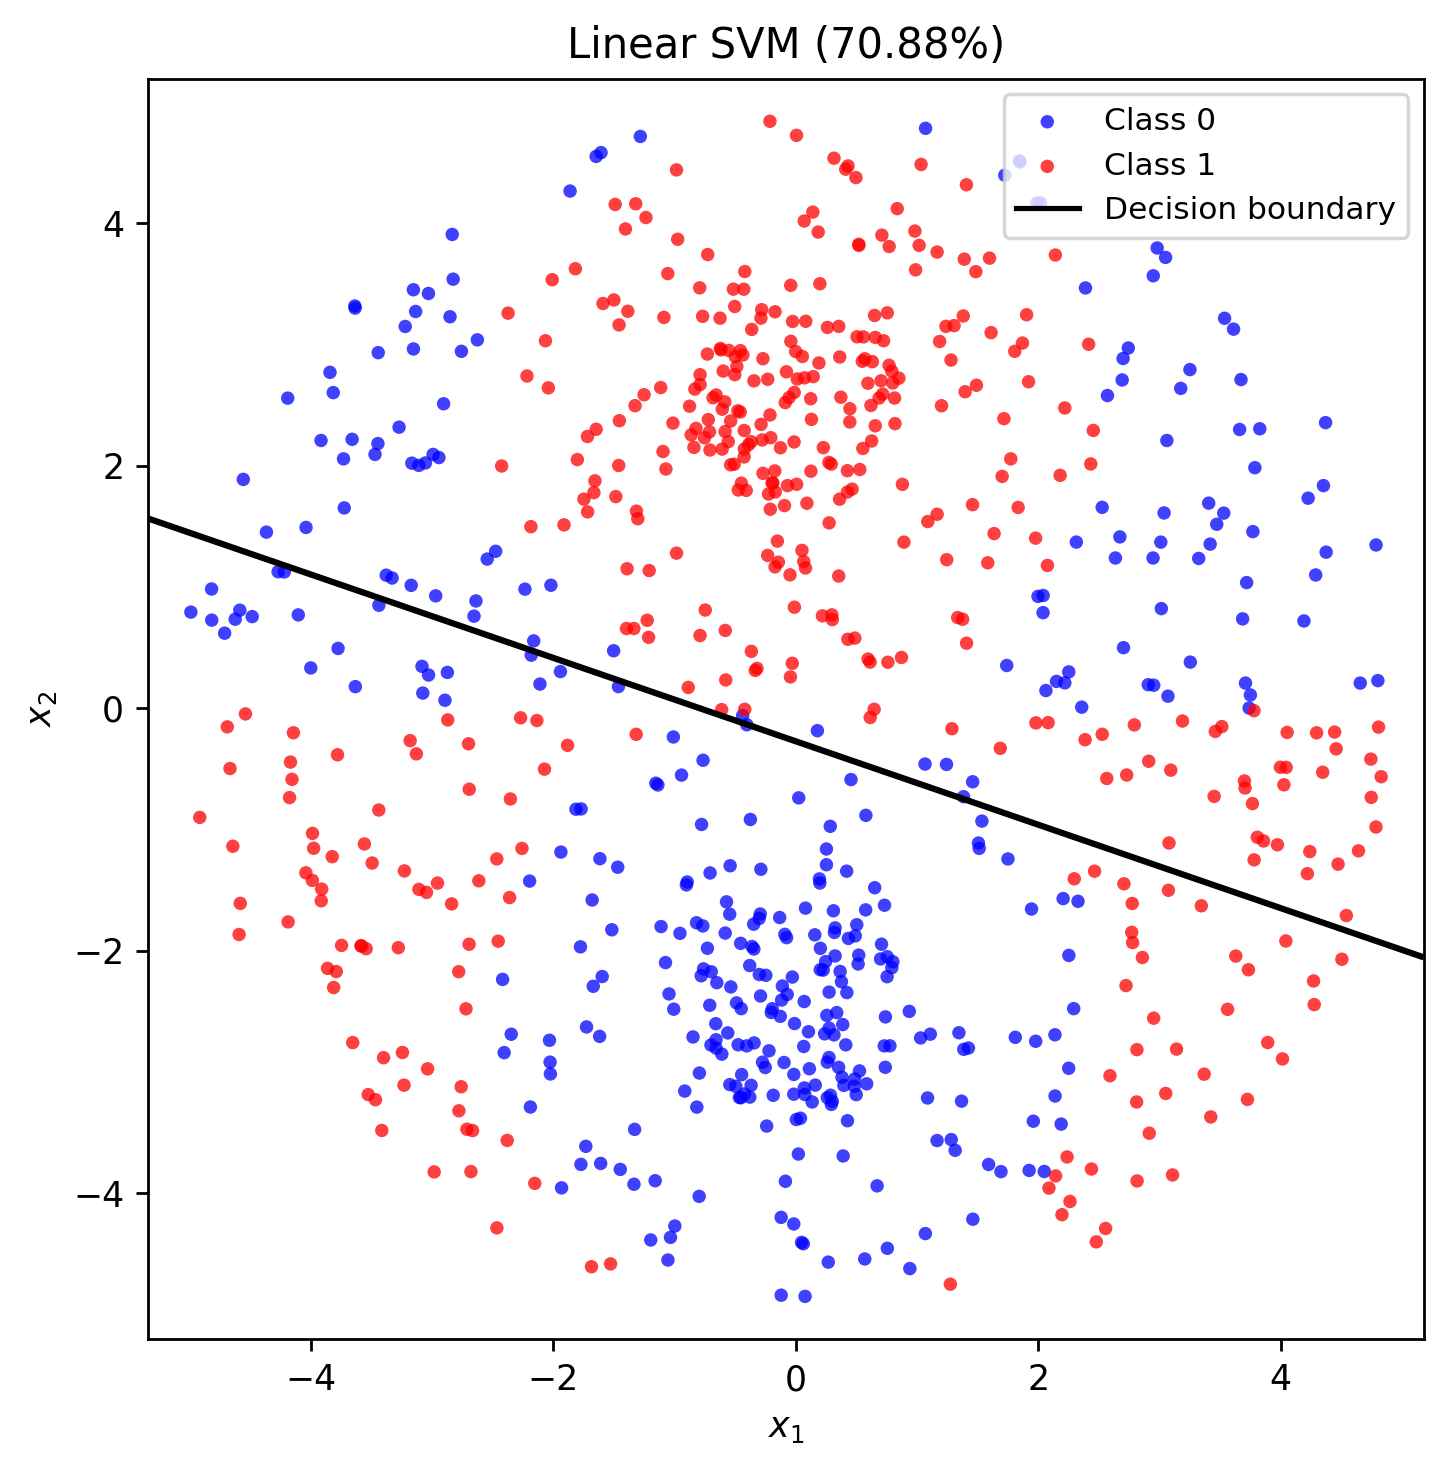

In [6]:
linear_grid = [dict(C=C) for C in [0.01, 0.1, 1, 10, 100]]
linear, linear_params, linear_table = search_svm('linear', linear_grid)
display(linear_table)
report_svm(linear, linear_params)
print('Weights:', linear.coef_[0], 'Intercept:', linear.intercept_[0])
draw_boundary(linear.decision_function, f'Linear SVM ({linear.score(X,y):.2%})', 'q4c_linear_svm.png')

## 4(d) Gaussian (RBF) SVM
The kernel is exp(-gamma * ||x-z||^2), where gamma = 1/(2*sigma^2). A larger gamma gives a more localized kernel, while a larger C penalizes margin violations more strongly.

,C,gamma,accuracy,converged,support_vectors
34,100.0,5.0,1.00000,True,339
35,100.0,10.0,1.00000,True,504
41,1000.0,1.0,1.00000,True,70
42,1000.0,2.0,1.00000,True,134
43,1000.0,5.0,1.00000,True,336
44,1000.0,10.0,1.00000,True,504
25,10.0,5.0,0.99875,True,350
26,10.0,10.0,0.99875,True,513
33,100.0,2.0,0.99875,True,141
40,1000.0,0.5,0.99875,True,48


Chosen parameters: {'C': 100, 'gamma': 5}
Training accuracy: 100.0000%
Correct predictions: 800 / 800
Support vectors: 339
Solver converged: True
Iterations: [4037]
Confusion matrix (labels 0,1):
 [[377   0]
 [  0 423]]
Equivalent sigma: 0.31622776601683794


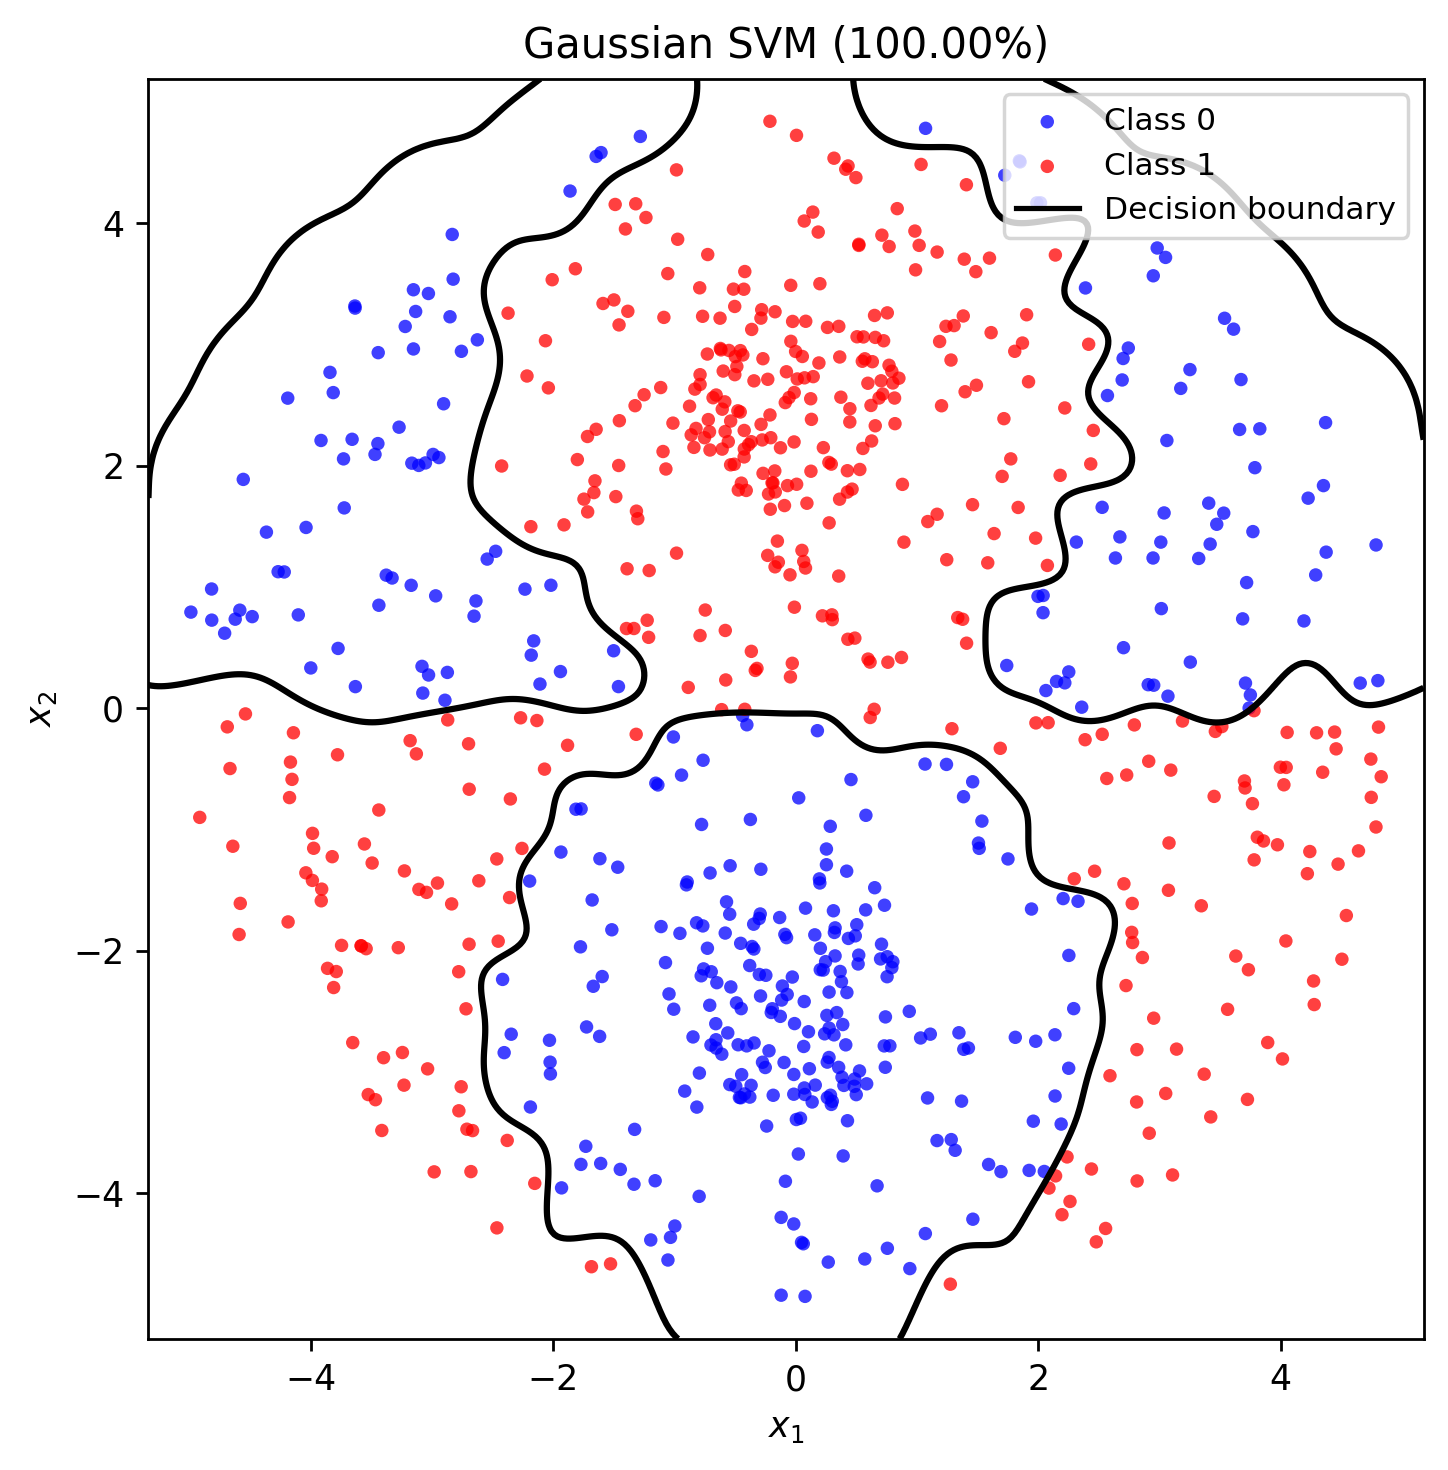

In [7]:
rbf_grid = [dict(C=C, gamma=g) for C in [0.1, 1, 10, 100, 1000]
            for g in [0.01, 0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10]]
rbf, rbf_params, rbf_table = search_svm('rbf', rbf_grid)
display(rbf_table.head(12))
report_svm(rbf, rbf_params)
print('Equivalent sigma:', np.sqrt(1/(2*rbf_params['gamma'])))
draw_boundary(rbf.decision_function, f'Gaussian SVM ({rbf.score(X,y):.2%})', 'q4d_gaussian_svm.png')

## 4(e) Polynomial SVM
The kernel is (gamma * x.T @ z + coef0)**degree. The degree controls polynomial order, gamma scales the dot product, and coef0 controls the contribution of lower-degree terms. A broader search at larger C and degree is included to approximate the best training fit.

C:\Users\harmi\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=2000000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\harmi\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=2000000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\harmi\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=2000000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\harmi\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=2000000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\harmi\AppData\Roaming\Pytho

,C,gamma,degree,coef0,accuracy,converged,support_vectors
149,10000.0,0.10,8,1,1.00000,True,30
150,10000.0,0.10,9,1,1.00000,True,32
151,10000.0,0.10,10,1,1.00000,True,30
129,100.0,0.10,10,1,0.99875,True,33
140,1000.0,0.10,9,1,0.99875,True,30
141,1000.0,0.10,10,1,0.99875,True,29
143,10000.0,0.05,7,1,0.99875,True,32
146,10000.0,0.05,10,1,0.99875,True,30
148,10000.0,0.10,7,1,0.99875,True,23
128,100.0,0.10,9,1,0.99750,True,37


Chosen parameters: {'C': 10000, 'gamma': 0.1, 'degree': 8, 'coef0': 1}
Training accuracy: 100.0000%
Correct predictions: 800 / 800
Support vectors: 30
Solver converged: True
Iterations: [1082493]
Confusion matrix (labels 0,1):
 [[377   0]
 [  0 423]]


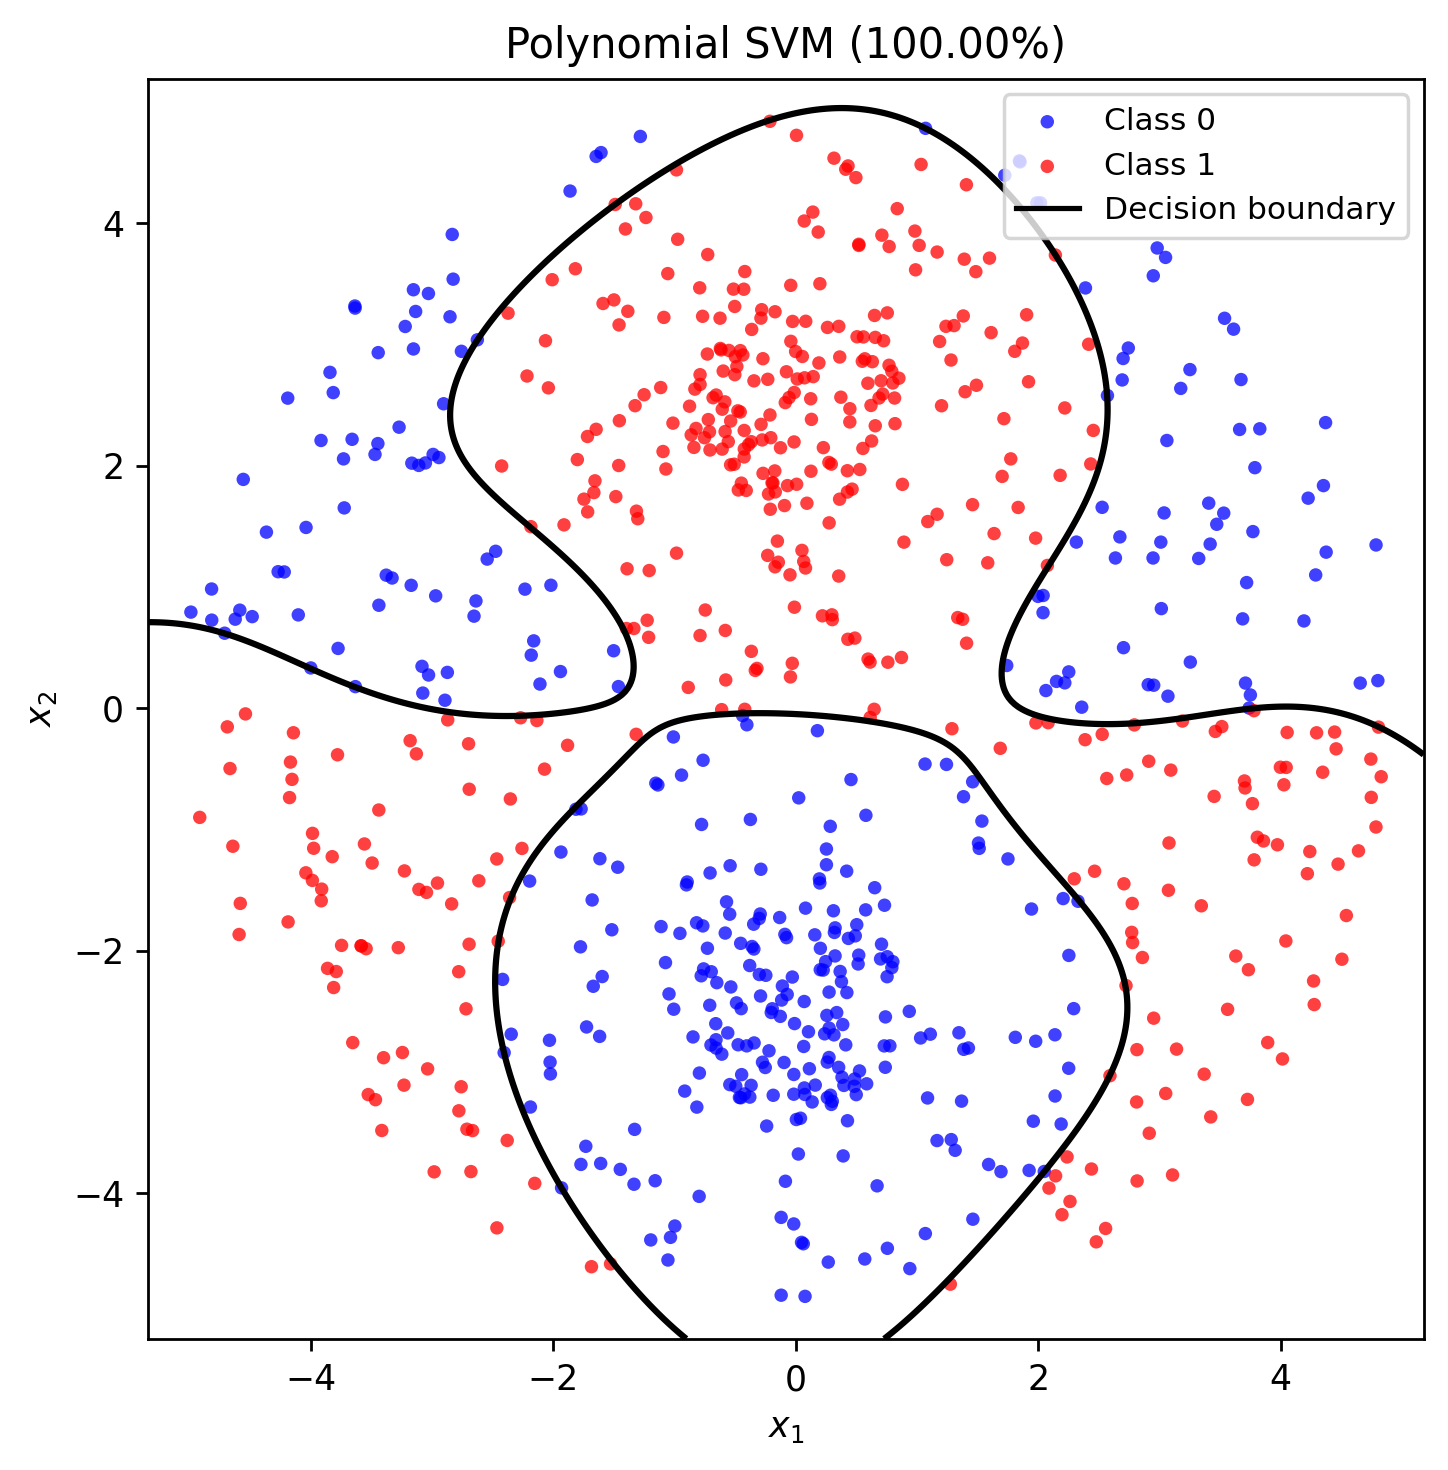

In [8]:
poly_grid = [dict(C=C, gamma=g, degree=d, coef0=r)
             for C in [0.1, 1, 10, 100] for g in [0.01, 0.05, 0.1]
             for d in range(2, 7) for r in [0, 1]]
poly_grid += [dict(C=C, gamma=g, degree=d, coef0=1)
              for C in [100, 1000, 10000] for g in [0.05, 0.1]
              for d in range(6 if C > 100 else 7, 13 if C == 100 else 11)]
poly, poly_params, poly_table = search_svm('poly', poly_grid)
display(poly_table.head(12))
report_svm(poly, poly_params)
draw_boundary(poly.decision_function, f'Polynomial SVM ({poly.score(X,y):.2%})', 'q4e_polynomial_svm.png')

## Final comparison

In [9]:
summary = pd.DataFrame([
    ('Linear logistic regression', accuracy_score(y, log_pred), np.sum(log_pred == y)),
    ('Linear SVM', linear.score(X,y), np.sum(linear.predict(X)==y)),
    ('Gaussian SVM', rbf.score(X,y), np.sum(rbf.predict(X)==y)),
    ('Polynomial SVM', poly.score(X,y), np.sum(poly.predict(X)==y))],
    columns=['Model', 'Training accuracy', 'Correct predictions'])
display(summary)


,Model,Training accuracy,Correct predictions
0,Linear logistic regression,0.67000,536
1,Linear SVM,0.70875,567
2,Gaussian SVM,1.00000,800
3,Polynomial SVM,1.00000,800


## Optimization diagnostics


In [10]:
# Training objective diagnostics for the three selected SVMs.
t = 2*y - 1
for name, model in [('Linear SVM', linear), ('Gaussian SVM', rbf),
                    ('Polynomial SVM', poly)]:
    scores = model.decision_function(X)
    hinge = np.maximum(0, 1 - t * scores)
    # Signed dual coefficients are alpha_i * t_i.
    # w = sum_i alpha_i * t_i * phi(x_i); compute its squared norm
    # from the kernel expansion without explicitly constructing phi.
    signed_dual = model.dual_coef_.ravel()
    norm_sq = signed_dual @ (model.decision_function(model.support_vectors_) - model.intercept_[0])
    objective = 0.5 * norm_sq + model.C * hinge.sum()
    print(f'{name}: mean hinge loss = {hinge.mean():.9f}; primal objective = {objective:.6f}')


Linear SVM: mean hinge loss = 0.721920490; primal objective = 5775.445538
Gaussian SVM: mean hinge loss = 0.000507125; primal objective = 356.286220
Polynomial SVM: mean hinge loss = 0.000574850; primal objective = 16658.776226
